In [3]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [11]:
df_raw = pd.read_csv("D:/project eyehealth predicator/processed_dataset.csv")
df=pd.read_csv("D:/project eyehealth predicator/processed_dataset.csv")

In [12]:
print("\n→ df.info()")
df_raw.info()
print("\n→ Missing Values")
print(df_raw.isnull().sum())
print("\n→ df.describe()")
print(df_raw.describe())


→ df.info()
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Unnamed: 0                20000 non-null  int64  
 1   name                      20000 non-null  str    
 2   age                       20000 non-null  int64  
 3   has_eye_disease           20000 non-null  bool   
 4   has_diabetic_retinopathy  20000 non-null  bool   
 5   sugar_percentage          20000 non-null  float64
 6   glucose_percentage        20000 non-null  float64
 7   cholesterol_percentage    20000 non-null  float64
 8   obesity_percentage        20000 non-null  float64
 9   blood_pressure            20000 non-null  str    
 10  heart_rate                20000 non-null  int64  
 11  systolic                  20000 non-null  int64  
 12  diastolic                 20000 non-null  int64  
 13  bp_category               20000 non-null  str    
 14  obes

In [13]:
df = df.drop(columns=['Unnamed: 0','name'],errors='ignore')

In [14]:
df = df.drop('blood_pressure', axis=1)

In [15]:
cols = ['obesity_group','bp_category']

dummy = pd.get_dummies(df[cols]).astype(int)
df = pd.concat([df,dummy],axis=1)
df = df.drop(columns=cols)

In [16]:
# Preprocessing dataset
print("\n→ df.info()")
df.info()
print("\n→ Missing Values")
print(df.isnull().sum())
print("\n→ df.describe()")
print(df.describe())


→ df.info()
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age                        20000 non-null  int64  
 1   has_eye_disease            20000 non-null  bool   
 2   has_diabetic_retinopathy   20000 non-null  bool   
 3   sugar_percentage           20000 non-null  float64
 4   glucose_percentage         20000 non-null  float64
 5   cholesterol_percentage     20000 non-null  float64
 6   obesity_percentage         20000 non-null  float64
 7   heart_rate                 20000 non-null  int64  
 8   systolic                   20000 non-null  int64  
 9   diastolic                  20000 non-null  int64  
 10  metabolic_risk_count       20000 non-null  int64  
 11  metabolic_syndrome_flag    20000 non-null  bool   
 12  health_risk_score          20000 non-null  float64
 13  obesity_group_normal       20000 non-null  i

In [19]:
print("Feature engineering completed on both datasets!")
print("Final cleaned datasets ready!")
print(f"Raw cleaned shape: {df_raw.shape}")
print(f"Processed cleaned shape: {df.shape}")
print("Sample from Processed cleaned dataset:")
print(df.head(5))

Feature engineering completed on both datasets!
Final cleaned datasets ready!
Raw cleaned shape: (20000, 18)
Processed cleaned shape: (20000, 21)
Sample from Processed cleaned dataset:
   age  has_eye_disease  has_diabetic_retinopathy  sugar_percentage  \
0   39            False                     False              5.70   
1   67             True                     False              8.72   
2   44             True                     False             13.83   
3   46             True                      True              9.48   
4   39            False                     False              5.60   

   glucose_percentage  cholesterol_percentage  obesity_percentage  heart_rate  \
0              147.48                  164.45               32.94          94   
1               91.52                  235.62               39.58          68   
2              160.17                  299.13               38.45          67   
3              106.84                  236.75               29.1

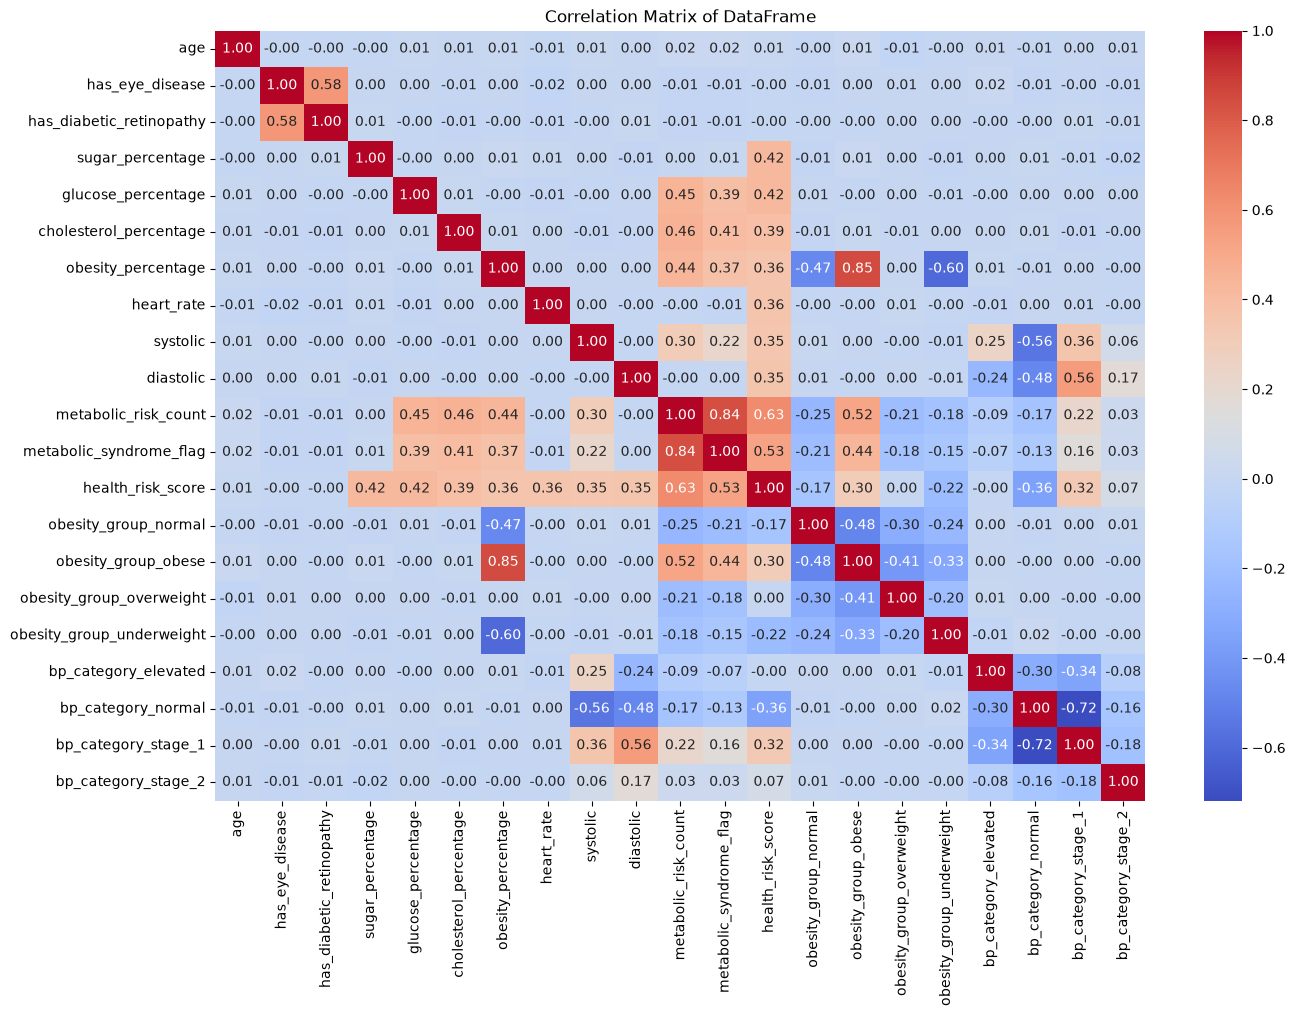

In [20]:
#Visualizing
plt.figure(figsize=(15, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of DataFrame')
plt.show()

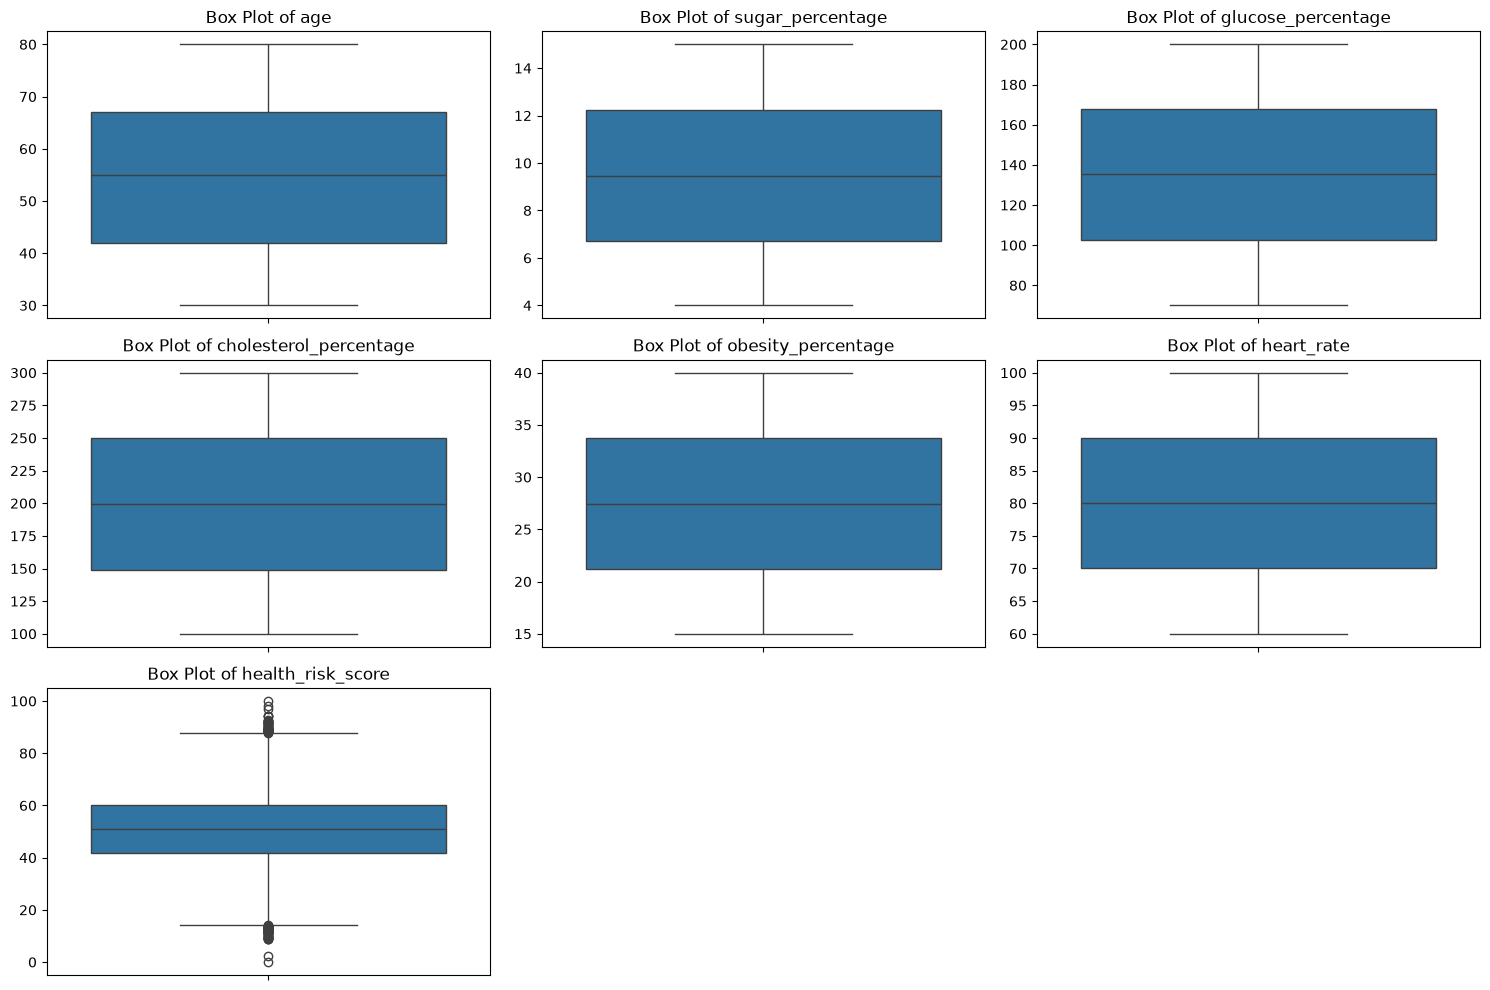

In [21]:
numerical_cols = ['age', 'sugar_percentage', 'glucose_percentage', 'cholesterol_percentage', 'obesity_percentage', 'heart_rate', 'health_risk_score']
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

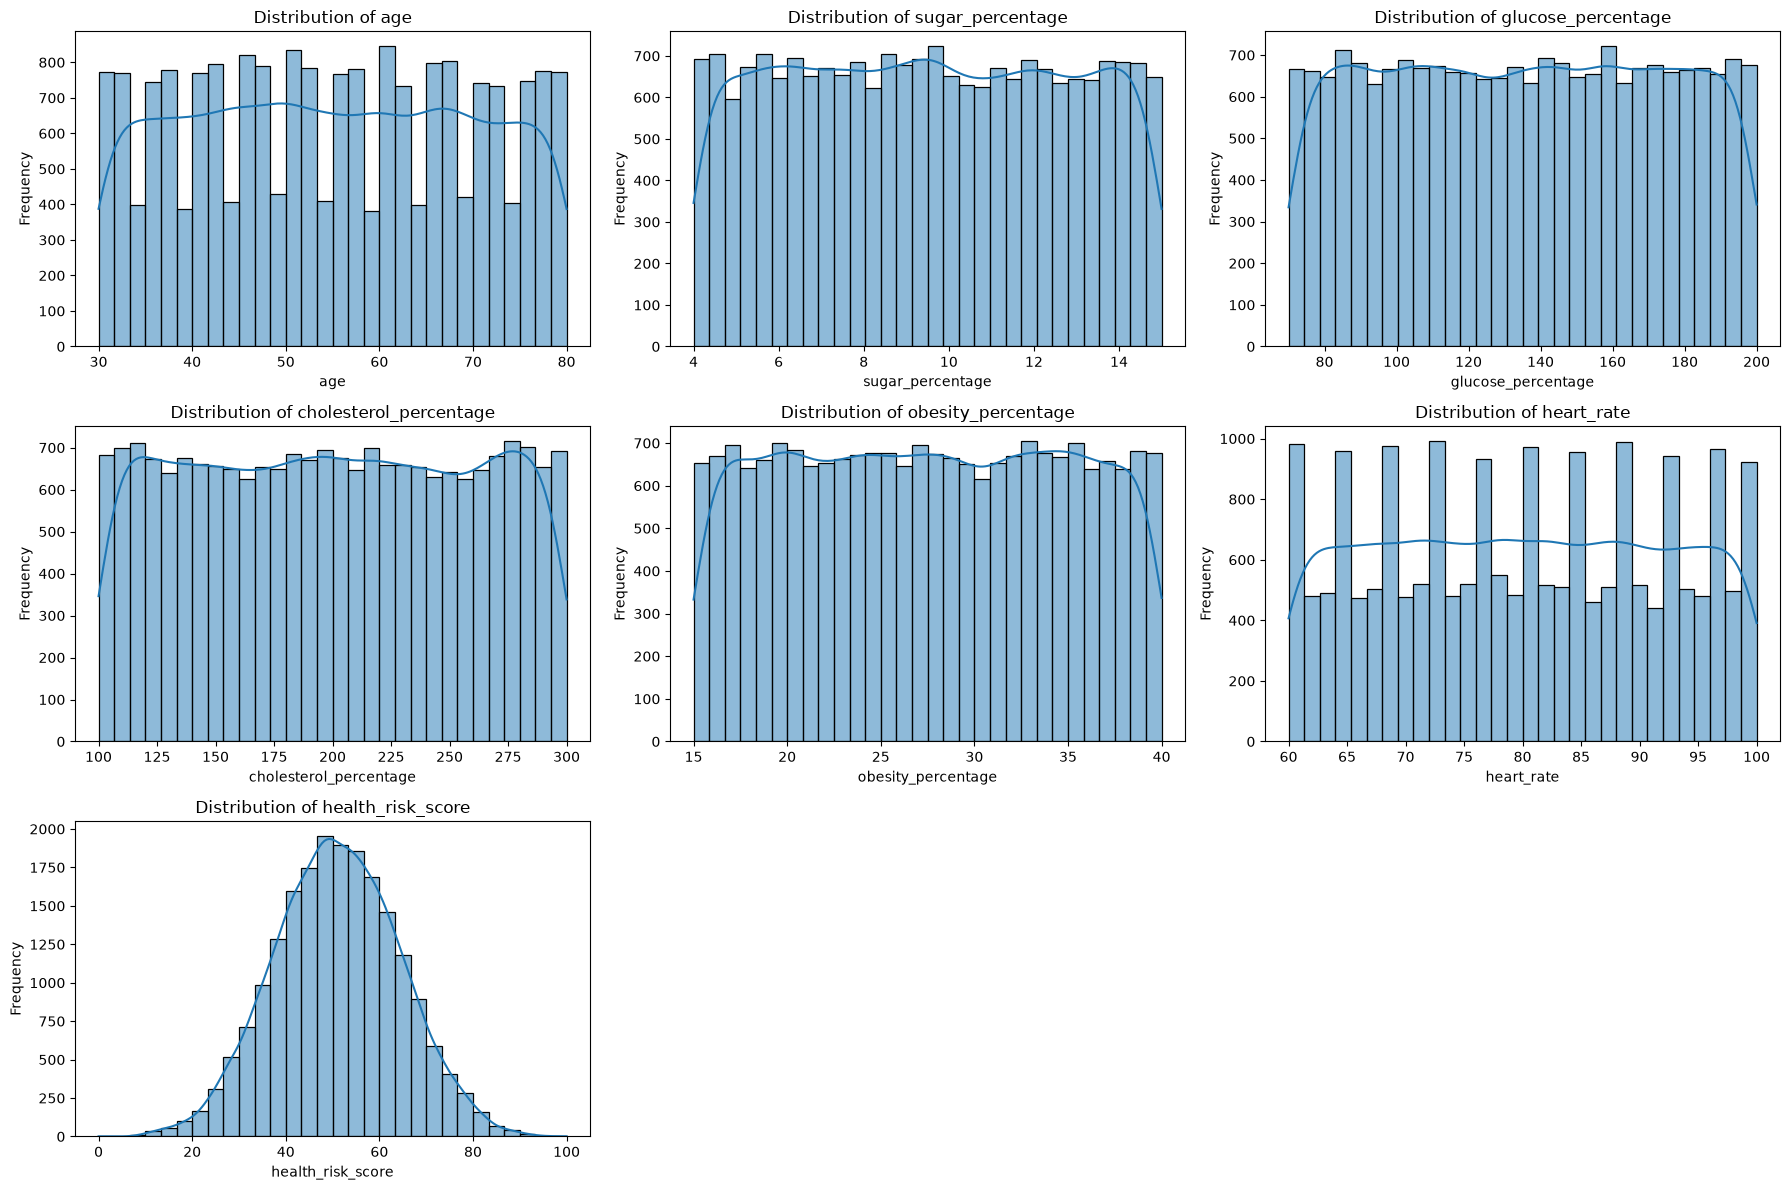

In [22]:
numerical_cols = ['age', 'sugar_percentage', 'glucose_percentage', 'cholesterol_percentage', 'obesity_percentage', 'heart_rate', 'health_risk_score']
plt.figure(figsize=(18, 12))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [23]:
X = df.drop('has_eye_disease', axis=1)
y = df['has_eye_disease']

print("Columns in X after dropping 'blood_pressure' and 'has_eye_disease':")
print(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X,y,train_size=0.8,random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Columns in X after dropping 'blood_pressure' and 'has_eye_disease':
Index(['age', 'has_diabetic_retinopathy', 'sugar_percentage',
       'glucose_percentage', 'cholesterol_percentage', 'obesity_percentage',
       'heart_rate', 'systolic', 'diastolic', 'metabolic_risk_count',
       'metabolic_syndrome_flag', 'health_risk_score', 'obesity_group_normal',
       'obesity_group_obese', 'obesity_group_overweight',
       'obesity_group_underweight', 'bp_category_elevated',
       'bp_category_normal', 'bp_category_stage_1', 'bp_category_stage_2'],
      dtype='str')


In [24]:
cv_auc = cross_val_score(
    LogisticRegression(solver='liblinear'),
    X,
    y,
    cv=5,
    scoring='roc_auc'
)

print("Mean CV ROC-AUC:", cv_auc.mean())

Mean CV ROC-AUC: 0.7497862638785955


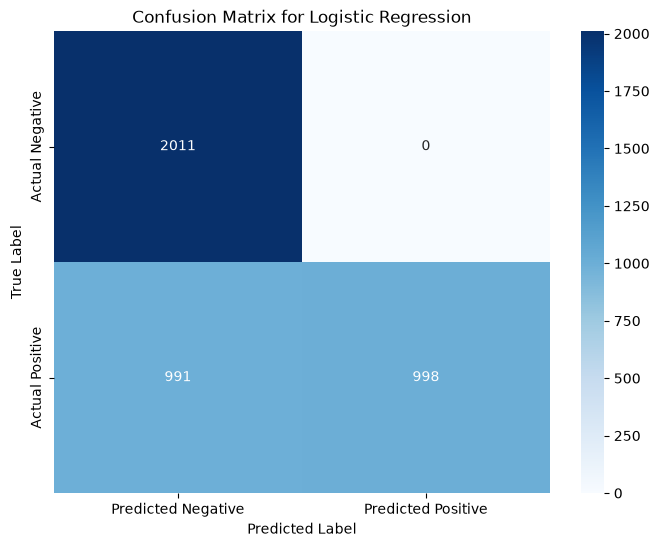

In [25]:
model = LogisticRegression(random_state=42, solver='liblinear') # liblinear is good for small datasets and binary classification
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Logistic Regression')
plt.show()

In [26]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC AUC: {roc_auc:.4f}")

Accuracy: 0.7522
Precision: 1.0000
Recall: 0.5018
F1-Score: 0.6682
ROC AUC: 0.7604


In [27]:
model_performance = {}
print("Initialized a dictionary to store model performance metrics.")

Initialized a dictionary to store model performance metrics.


--- RandomForestClassifier Metrics ---
Accuracy: 0.7435
Precision: 0.9454
Recall: 0.5138
F1-Score: 0.6658
ROC AUC: 0.7506


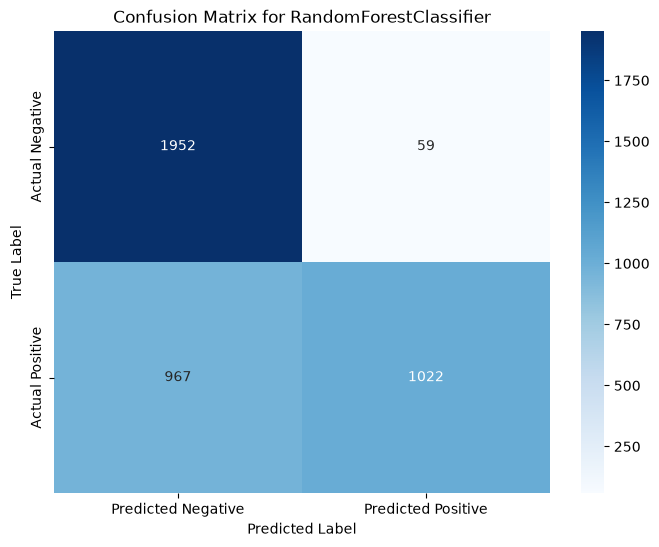

In [29]:
model_name = 'RandomForestClassifier'
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)
roc_auc_rf = roc_auc_score(y_test, y_proba_rf)

model_performance[model_name] = {
    'Accuracy': accuracy_rf,
    'Precision': precision_rf,
    'Recall': recall_rf,
    'F1-Score': f1_rf,
    'ROC AUC': roc_auc_rf
}

print(f"--- {model_name} Metrics ---")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")
print(f"ROC AUC: {roc_auc_rf:.4f}")

cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix for {model_name}')
plt.show()

In [30]:
importances = rf_model.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)

feat_imp.head(10)

has_diabetic_retinopathy    0.318663
cholesterol_percentage      0.078570
glucose_percentage          0.078042
health_risk_score           0.078010
sugar_percentage            0.077033
obesity_percentage          0.075520
age                         0.063351
heart_rate                  0.061278
systolic                    0.057919
diastolic                   0.055379
dtype: float64

--- GradientBoostingClassifier Metrics ---
Accuracy: 0.7515
Precision: 0.9960
Recall: 0.5023
F1-Score: 0.6678
ROC AUC: 0.7489


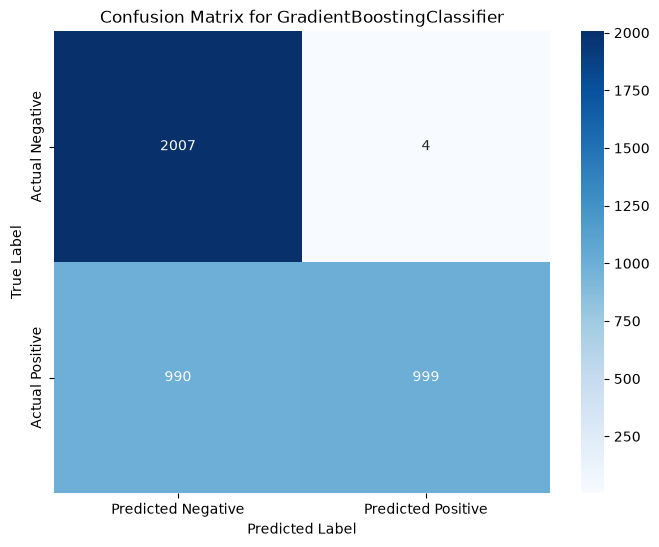

In [31]:
model_name = 'GradientBoostingClassifier'
gbc_model = GradientBoostingClassifier(random_state=42)
gbc_model.fit(X_train, y_train)

y_pred_gbc = gbc_model.predict(X_test)
y_proba_gbc = gbc_model.predict_proba(X_test)[:, 1]

accuracy_gbc = accuracy_score(y_test, y_pred_gbc)
precision_gbc = precision_score(y_test, y_pred_gbc)
recall_gbc = recall_score(y_test, y_pred_gbc)
f1_gbc = f1_score(y_test, y_pred_gbc)
roc_auc_gbc = roc_auc_score(y_test, y_proba_gbc)

model_performance[model_name] = {
    'Accuracy': accuracy_gbc,
    'Precision': precision_gbc,
    'Recall': recall_gbc,
    'F1-Score': f1_gbc,
    'ROC AUC': roc_auc_gbc
}

print(f"--- {model_name} Metrics ---")
print(f"Accuracy: {accuracy_gbc:.4f}")
print(f"Precision: {precision_gbc:.4f}")
print(f"Recall: {recall_gbc:.4f}")
print(f"F1-Score: {f1_gbc:.4f}")
print(f"ROC AUC: {roc_auc_gbc:.4f}")

cm_gbc = confusion_matrix(y_test, y_pred_gbc)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_gbc, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Negative', 'Predicted Positive'],
            yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix for {model_name}')
plt.show()

In [32]:
model_comparison_df = pd.DataFrame.from_dict(model_performance, orient='index')
print(model_comparison_df)

                            Accuracy  Precision    Recall  F1-Score   ROC AUC
RandomForestClassifier        0.7435   0.945421  0.513826  0.665798  0.750597
GradientBoostingClassifier    0.7515   0.996012  0.502262  0.667781  0.748857
